# Test Default, Xavier, and Uniform Initialization on MNIST Dataset with Tanh Activation — worked study copy

Answers prepared for revision with AI assistance. IBM / Skills Network source notices and embedded instructor explanations are retained. This is not a course submission.

Code completion and execution are tracked separately in the [solution progress report](../../../docs/SOLUTION_PROGRESS.md). Training may require a separate environment, external data, compute or provider credentials.

[Original reference](../../../courses/05-deep-learning-with-pytorch/notebooks/test-default-xavier-and-uniform-initialization-on-mnist-dataset-with-tanh-activation.ipynb) · [Course notes](../../../courses/05-deep-learning-with-pytorch/README.md)

**BOUNDED SMOKE RUN:** seed 42; CSVs sampled to at most 5,000 rows; one grid setting with two folds; training budgets capped; DataLoaders limited to 12 batches. These outputs are execution checks, not full-run model evaluations.

In [1]:
import os, itertools, random
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['TF_NUM_INTEROP_THREADS'] = '1'
os.environ['TF_NUM_INTRAOP_THREADS'] = '1'
import numpy as np
np.random.seed(42)
random.seed(42)
import pandas as pd
_read_csv = pd.read_csv
def _bounded_csv(*args, **kwargs):
    data = _read_csv(*args, **kwargs)
    return data.sample(n=5000,random_state=42) if len(data)>5000 else data
pd.read_csv = _bounded_csv
from sklearn.model_selection import GridSearchCV
_grid_fit = GridSearchCV.fit
def _bounded_grid(self, *args, **kwargs):
    grids = self.param_grid if isinstance(self.param_grid,list) else [self.param_grid]
    self.param_grid = [{k:list(v)[:1] for k,v in grid.items()} for grid in grids[:1]]
    self.cv = 2
    self.n_jobs = 1
    self.verbose = 0
    return _grid_fit(self,*args,**kwargs)
GridSearchCV.fit = _bounded_grid
try:
    import torch
except ImportError:
    torch = None
if torch is not None:
    torch.manual_seed(42)
    torch.set_num_threads(1)
    _loader_iter = torch.utils.data.DataLoader.__iter__
    def _bounded_loader(self):
        return itertools.islice(_loader_iter(self),12)
    torch.utils.data.DataLoader.__iter__ = _bounded_loader


<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


<h1>Test Default, Xavier, and Uniform Initialization on MNIST Dataset with Tanh Activation</h1>



<h3>Objectives</h3>    

<ul>
    <li>Define several neural networks, criterion functions, and optimizers</li>
    <li>Test Default, Xavier, and Uniform Initializations</li>
    <li>Analyze the results</li>


<p>Estimated Time Needed: <strong>25 mins</strong></p>


<h2>Table of Contents</h2>
In this lab, you will test PyTroch Default Initialization, Xavier Initialization and Uniform Initialization on the MNIST dataset. 

<ul>
    <li><a href="#Preparation">Preparation</a></li>
    <li><a href="#Neural-Network-Module-and-Training-Function">Neural Network Module and Training Function</a></li>
    <li><a href="#Make-Some-Data">Make Some Data</a></li>
    <li><a href="#Define-Neural-Network,-Criterion-Function,-Optimizer,-and-Train-the-Model">Define Neural Network, Criterion Function, Optimizer, and Train the Model</a></li>
    <li><a href="#Test-PyTorch-Default-Initialization,-Xavier-Initialization,-and-Uniform-Initialization">Test PyTorch Default Initialization, Xavier Initialization, and Uniform Initialization</a></li>
    <li><a href="#Analyze-Results">Analyze Results</a></li>
</ul>

<hr>


<h2>Preparation</h2>


We'll need the following libraries:  


In [2]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torchvision.datasets as dsets
import matplotlib.pylab as plt
import numpy as np
torch.manual_seed(0)

Matplotlib is building the font cache; this may take a moment.


<!--Empty Space for separating topics-->


<a name="Model"><h2 id="Model">Neural Network Module and Training Function</h2> </a>


Define the neural network module or class with Xavier Initialization


In [3]:
class Net_Xavier(nn.Module):

    def __init__(self, Layers):
        super(Net_Xavier, self).__init__()
        self.hidden = nn.ModuleList()
        for input_size, output_size in zip(Layers, Layers[1:]):
            linear = nn.Linear(input_size, output_size)
            torch.nn.init.xavier_uniform_(linear.weight)
            self.hidden.append(linear)

    def forward(self, x):
        L = len(self.hidden)
        for l, linear_transform in zip(range(L), self.hidden):
            if l < L - 1:
                x = torch.tanh(linear_transform(x))
            else:
                x = linear_transform(x)
        return x

Define the neural network module with Uniform Initialization:


In [4]:
class Net_Uniform(nn.Module):

    def __init__(self, Layers):
        super(Net_Uniform, self).__init__()
        self.hidden = nn.ModuleList()
        for input_size, output_size in zip(Layers, Layers[1:]):
            linear = nn.Linear(input_size, output_size)
            linear.weight.data.uniform_(0, 1)
            self.hidden.append(linear)

    def forward(self, x):
        L = len(self.hidden)
        for l, linear_transform in zip(range(L), self.hidden):
            if l < L - 1:
                x = torch.tanh(linear_transform(x))
            else:
                x = linear_transform(x)
        return x

Define the neural network module with PyTroch Default Initialization


In [5]:
class Net(nn.Module):

    def __init__(self, Layers):
        super(Net, self).__init__()
        self.hidden = nn.ModuleList()
        for input_size, output_size in zip(Layers, Layers[1:]):
            linear = nn.Linear(input_size, output_size)
            self.hidden.append(linear)

    def forward(self, x):
        L = len(self.hidden)
        for l, linear_transform in zip(range(L), self.hidden):
            if l < L - 1:
                x = torch.tanh(linear_transform(x))
            else:
                x = linear_transform(x)
        return x

Define a function to train the model, in this case the function returns a Python dictionary to store the training loss and accuracy on the validation data 


In [6]:
def train(model, criterion, train_loader, validation_loader, optimizer, epochs=2):
    i = 0
    loss_accuracy = {'training_loss': [], 'validation_accuracy': []}
    for epoch in itertools.islice(range(epochs), 2):
        for i, (x, y) in enumerate(train_loader):
            optimizer.zero_grad()
            z = model(x.view(-1, 28 * 28))
            loss = criterion(z, y)
            loss.backward()
            optimizer.step()
            loss_accuracy['training_loss'].append(loss.data.item())
        correct = 0
        for x, y in validation_loader:
            yhat = model(x.view(-1, 28 * 28))
            _, label = torch.max(yhat, 1)
            correct += (label == y).sum().item()
        accuracy = 100 * (correct / len(validation_dataset))
        loss_accuracy['validation_accuracy'].append(accuracy)
    return loss_accuracy

<!--Empty Space for separating topics-->


<a name="Make"><h2 id="Makeup_Data">Make Some Data</h2></a>


Load the training dataset by setting the parameters <code>train </code> to <code>True</code> and convert it to a tensor  by placing a transform object int the argument <code>transform</code>


In [7]:
train_dataset = dsets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<00:48, 204kB/s]

  1%|          | 98.3k/9.91M [00:00<00:31, 311kB/s]

  2%|▏         | 164k/9.91M [00:00<00:26, 370kB/s] 

  4%|▍         | 393k/9.91M [00:00<00:12, 746kB/s]

  8%|▊         | 754k/9.91M [00:00<00:06, 1.36MB/s]

... (21 outputs left out)

 95%|█████████▌| 1.57M/1.65M [00:00<00:00, 2.90MB/s]

100%|██████████| 1.65M/1.65M [00:01<00:00, 1.62MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 1.25MB/s]

Load the testing dataset by setting the parameters <code>train</code> to <code>False</code> and convert it to a tensor  by placing a transform object int the argument <code>transform</code>


In [8]:
validation_dataset = dsets.MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())

Create the training-data loader and the validation-data loader object 


In [9]:
train_loader = torch.utils.data.DataLoader(dataset=train_dataset, batch_size=2000, shuffle=True)
validation_loader = torch.utils.data.DataLoader(dataset=validation_dataset, batch_size=5000, shuffle=False)

<!--Empty Space for separating topics-->


<a name="Cost"><h2 id="Cost">Define Neural Network, Criterion Function, Optimizer, and Train the Model</h2></a>


Create the criterion function


In [10]:
criterion = nn.CrossEntropyLoss()

Create the model with 100 hidden layers  


In [11]:
input_dim = 28 * 28
output_dim = 10
layers = [input_dim, 100, 10, 100, 10, 100, output_dim]
epochs = 2

<!--Empty Space for separating topics-->


<h2>Test PyTorch Default Initialization, Xavier Initialization, and Uniform Initialization</h2>


Train the network using PyTorch Default Initialization


In [12]:
model = Net(layers)
learning_rate = 0.01
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
training_results = train(model, criterion, train_loader, validation_loader, optimizer, epochs=min(2, epochs))

Train the network using Xavier Initialization function


In [13]:
model_Xavier = Net_Xavier(layers)
optimizer = torch.optim.SGD(model_Xavier.parameters(), lr=learning_rate)
training_results_Xavier = train(model_Xavier, criterion, train_loader, validation_loader, optimizer, epochs=min(2, epochs))

Train the network using Uniform Initialization


In [14]:
model_Uniform = Net_Uniform(layers)
optimizer = torch.optim.SGD(model_Uniform.parameters(), lr=learning_rate)
training_results_Uniform = train(model_Uniform, criterion, train_loader, validation_loader, optimizer, epochs=min(2, epochs))

<!--Empty Space for separating topics-->


<h2>Analyze Results</h2>


Compare the training loss for each initialization


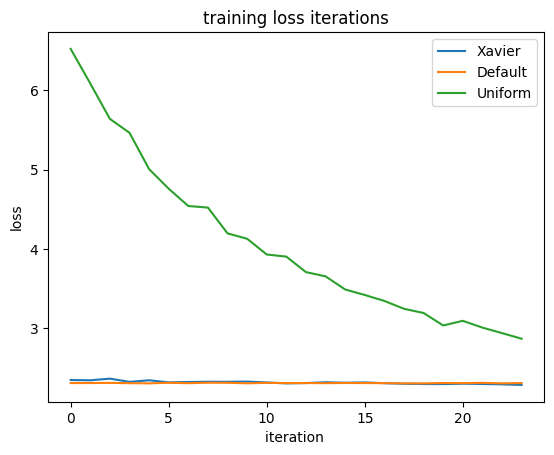

In [15]:
plt.plot(training_results_Xavier['training_loss'], label='Xavier')
plt.plot(training_results['training_loss'], label='Default')
plt.plot(training_results_Uniform['training_loss'], label='Uniform')
plt.ylabel('loss')
plt.xlabel('iteration ')
plt.title('training loss iterations')
plt.legend()

compare the validation loss for each model  


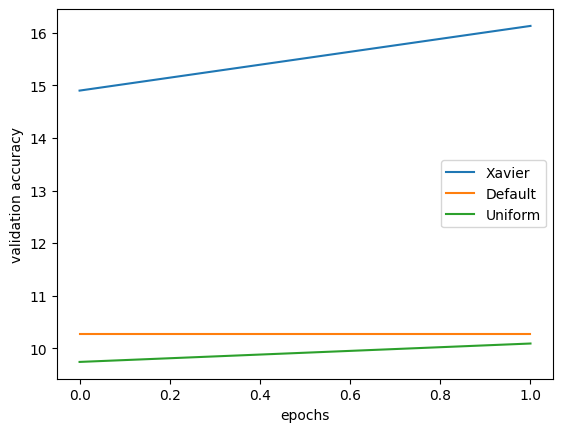

In [16]:
plt.plot(training_results_Xavier['validation_accuracy'], label='Xavier')
plt.plot(training_results['validation_accuracy'], label='Default')
plt.plot(training_results_Uniform['validation_accuracy'], label='Uniform')
plt.ylabel('validation accuracy')
plt.xlabel('epochs')
plt.legend()

<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD. 


Other contributors: <a href="https://www.linkedin.com/in/michelleccarey/">Michelle Carey</a>, <a href="https://www.linkedin.com/in/jiahui-mavis-zhou-a4537814a">Mavis Zhou</a>


<!--
## Change Log

|  Date (YYYY-MM-DD) |  Version | Changed By  |  Change Description |
|---|---|---|---|
| 2020-09-23  | 2.0  | Srishti  |  Migrated Lab to Markdown and added to course repo in GitLab |



<hr>
-->

## <h3 align="center"> &#169; IBM Corporation. All rights reserved. <h3/>
